# RAID Aggregate — Architecture Development and Training Notebook

This notebook brings together the **model architecture, training loop, and diagnostics** for the Intel SKU aggregate cold-start experiment. Once the architecture and training behavior are validated here, the model and training cells can be moved into `src/models/raid.py` and `scripts/train_raid_aggregate.py`.

## Protocol and assumptions

- Target: aggregate weekly `customer_orders`; forecast window: 13 weeks from the SKU's launch week.
- Train/test split: the saved SKU-held-out split (seed 42). The 27 launch-ineligible SKUs remain in training, and 35 eligible SKUs are held out for evaluation.
- This is a **SKU-held-out cold-start simulation, not strict historical backtesting**. Test labels are not used for fitting or checkpoint selection.
- Retrieval donors must be training SKUs launched strictly before the target origin, with a complete 13-week history immediately before that origin. The target is excluded from its own donors.
- Metadata embeddings are frozen. Graph learning, scale/mean prediction, and diffusion refinement are trainable.
- The notebook makes numerical stabilization explicit: demand is divided by a single scale computed from observed training-SKU demand only. Forecasts are converted back to original demand units for reporting. This is a declared implementation choice to make residual diffusion numerically coherent, not a claim that the paper specifies this exact transform.
- Donor means and standard deviations are computed from each donor's observed history strictly before the episode origin, not from the 13-week donor window alone.
- Main objective follows the stated paper objective: noise-prediction loss + `0.01 × base MSE`. No extra final reconstruction loss is used in the primary run. A gate auxiliary loss, if tested, must be a separately labelled ablation.
- Sampling uses a respaced stochastic DDPM posterior update. The exact fast-sampling details in the paper are underspecified; this is a paper-aligned implementation assumption that should be documented.

In [1]:
import sys, os, json, math, time, random, platform, subprocess
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Pandas:", pd.__version__)

Python: /home/aakash/miniconda3/envs/intel-embeddings/bin/python
PyTorch: 2.14.1+cu130
CUDA available: True
Pandas: 2.3.3


In [2]:
# Find repository root even if this notebook is under notebooks/debugging.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "configs/intel_sku/raid_aggregate.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find repo root. Open this notebook from the repository or put it under notebooks/debugging/."
    )
sys.path.insert(0, str(ROOT))
CFG_PATH = ROOT / "configs/intel_sku/raid_aggregate.json"
cfg = json.loads(CFG_PATH.read_text(encoding="utf-8"))
d, o, m, tcfg = cfg["data"], cfg["outputs"], cfg["model"], cfg["training"]
H = int(cfg["experiment"]["forecast_window_weeks"])
SEED = int(cfg["experiment"]["random_seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

metadata = pd.read_csv(ROOT / d["sku_metadata_path"])
demand = pd.read_csv(ROOT / d["aggregate_demand_path"])
cases = pd.read_csv(ROOT / d["cases_path"])
split_dir = ROOT / o["split_dir"]
train_skus = pd.read_csv(split_dir / "train_skus.csv")["sku"].astype(str).tolist()
test_skus = pd.read_csv(split_dir / "test_skus.csv")["sku"].astype(str).tolist()
embeddings = np.load(ROOT / d["embedding_path"]).astype(np.float32)
embed_index = json.loads((ROOT / d["embedding_index_path"]).read_text(encoding="utf-8"))
embed_skus = [str(s) for s in embed_index["skus"]]
sku_to_idx = {sku: i for i, sku in enumerate(embed_skus)}

assert len(set(train_skus) & set(test_skus)) == 0
assert set(train_skus + test_skus) <= set(sku_to_idx)
assert embeddings.shape == (len(embed_skus), int(m["embedding_dim"]))
print("Root:", ROOT)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print(f"Train SKUs={len(train_skus)}, test SKUs={len(test_skus)}, H={H}")
print("Embedding shape:", embeddings.shape)

Root: /mnt/d/SEM 7/Honours by Research/GitHub_Sundial/ColdStart_Sundial
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Train SKUs=51, test SKUs=35, H=13
Embedding shape: (86, 1024)


## 1. Prepare a training-only numerical scale

We divide demand by the standard deviation of all observed values belonging to **training SKUs only**. We do not subtract the global mean, so zero demand remains zero. The same fixed scale is used for training and inference, and forecasts are multiplied by it before metrics are computed.

This is not a substitute for donor-specific shape normalization: donor-specific statistics are still computed separately at every origin.

In [3]:
series = {
    str(sku): group.set_index(d["week_column"])[d["target_column"]].sort_index()
    for sku, group in demand.groupby(d["sku_column"])
}
meta_by_sku = metadata.set_index(d["sku_column"], drop=False)

train_values = np.concatenate([
    series[s].dropna().to_numpy(dtype=np.float64)
    for s in train_skus if s in series
])
DEMAND_SCALE = float(np.std(train_values))
if not np.isfinite(DEMAND_SCALE) or DEMAND_SCALE <= 0:
    raise ValueError(f"Invalid training-only demand scale: {DEMAND_SCALE}")
print("Training-only demand std scale:", DEMAND_SCALE)
print("Raw train demand min/median/mean/max:",
      float(np.min(train_values)), float(np.median(train_values)),
      float(np.mean(train_values)), float(np.max(train_values)))

Training-only demand std scale: 61290.94844331183
Raw train demand min/median/mean/max: 0.0 22994.0 45238.35693710994 664203.0


## 2. RAID architecture

This model cell is the source of truth while developing the architecture. Important corrections relative to the first implementation:

- GATv2 aggregates the transformed neighbor-side values used in attention scoring.
- `DiT.context_proj` uses the configured bottleneck dimension rather than a hard-coded 16.
- `base_forecast` receives donor-global statistics computed from observations strictly before the episode origin.
- The diffusion residual target is detached from the base forecast's computation graph.
- The primary loss is only diffusion noise prediction plus the configured base MSE weight. Under this interpretation, the gate receives no direct gradient; this is a paper ambiguity to document, not silently repair.
- The DDPM sampler uses a respaced posterior update and restores the model's previous train/eval mode.

In [4]:
def sinusoidal_embedding(t: torch.Tensor, dim: int) -> torch.Tensor:
    half = dim // 2
    freq = torch.exp(
        -math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32)
        / max(half - 1, 1)
    )
    angle = t.float().unsqueeze(1) * freq.unsqueeze(0)
    out = torch.cat([torch.sin(angle), torch.cos(angle)], dim=1)
    return F.pad(out, (0, 1)) if dim % 2 else out


class GATv2Layer(nn.Module):
    """Dense masked GATv2 layer; suitable for the small 86-SKU graph."""
    def __init__(self, dim: int, heads: int = 4, dropout: float = 0.1):
        super().__init__()
        if dim % heads:
            raise ValueError("bottleneck_dim must be divisible by gat_heads")
        self.dim, self.heads, self.dh = dim, heads, dim // heads
        self.src = nn.Linear(dim, dim, bias=False)
        self.dst = nn.Linear(dim, dim, bias=False)
        self.attn = nn.Parameter(torch.empty(heads, self.dh))
        self.proj = nn.Linear(dim, dim)
        self.drop = nn.Dropout(dropout)
        nn.init.xavier_uniform_(self.attn)

    def forward(self, x, allowed):
        n = x.shape[0]
        src = self.src(x).view(n, self.heads, self.dh)
        dst = self.dst(x).view(n, self.heads, self.dh)
        pair = F.leaky_relu(src[:, None] + dst[None, :], 0.2)
        # logits[i, j, head] scores neighbor j when updating node i.
        logits = (pair * self.attn[None, None]).sum(-1)
        logits = logits.masked_fill(~allowed[:, :, None], torch.finfo(logits.dtype).min)
        alpha = self.drop(torch.softmax(logits, dim=1))  # [target_i, neighbor_j, head]
        msg = torch.einsum("ijh,jhd->ihd", alpha, dst).reshape(n, self.dim)
        return F.elu(self.proj(msg) + x)


class DiTBlock(nn.Module):
    def __init__(self, hidden=64, heads=4, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden, elementwise_affine=False)
        self.norm2 = nn.LayerNorm(hidden, elementwise_affine=False)
        self.attn = nn.MultiheadAttention(hidden, heads, dropout=dropout, batch_first=True)
        self.mlp = nn.Sequential(
            nn.Linear(hidden, 4 * hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(4 * hidden, hidden), nn.Dropout(dropout)
        )
        self.mod = nn.Sequential(nn.SiLU(), nn.Linear(hidden, 6 * hidden))
        nn.init.zeros_(self.mod[-1].weight)
        nn.init.zeros_(self.mod[-1].bias)

    def forward(self, x, cond):
        sa, sca, ga, sm, scm, gm = self.mod(cond).chunk(6, dim=-1)
        z = self.norm1(x) * (1 + sca[:, None]) + sa[:, None]
        x = x + ga[:, None] * self.attn(z, z, z, need_weights=False)[0]
        z = self.norm2(x) * (1 + scm[:, None]) + sm[:, None]
        return x + gm[:, None] * self.mlp(z)


class DiT(nn.Module):
    def __init__(self, horizon=13, bottleneck_dim=16, hidden=64, layers=4,
                 heads=4, time_dim=128, dropout=0.1):
        super().__init__()
        self.horizon = horizon
        self.in_proj = nn.Linear(1, hidden)
        self.pos = nn.Parameter(torch.randn(1, horizon, hidden) * 0.02)
        self.time_mlp = nn.Sequential(nn.Linear(time_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.context_proj = nn.Linear(bottleneck_dim, hidden)
        self.blocks = nn.ModuleList([DiTBlock(hidden, heads, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(hidden)
        self.out_proj = nn.Linear(hidden, 1)

    def forward(self, x, t, context):
        h = self.in_proj(x.unsqueeze(-1)) + self.pos
        t_emb = self.time_mlp(sinusoidal_embedding(t, self.time_mlp[0].in_features))
        cond = t_emb + self.context_proj(context)
        for block in self.blocks:
            h = block(h, cond)
        return self.out_proj(self.norm(h)).squeeze(-1)


class RAID(nn.Module):
    def __init__(self, horizon=13, embedding_dim=1024, bottleneck_dim=16, k=20,
                 gat_heads=4, gat_layers=2, dit_hidden=64, dit_layers=4, dit_heads=4,
                 dit_dropout=0.1, time_dim=128, diffusion_steps=50,
                 beta_start=1e-4, beta_end=0.02, shape_clamp=10.0, epsilon=1e-6,
                 base_loss_weight=0.01, gate_bias_init=-3.0):
        super().__init__()
        self.horizon, self.k = horizon, k
        self.bottleneck_dim = bottleneck_dim
        self.shape_clamp, self.eps = shape_clamp, epsilon
        self.base_loss_weight = base_loss_weight
        self.bottleneck = nn.Sequential(
            nn.LayerNorm(embedding_dim), nn.Linear(embedding_dim, bottleneck_dim), nn.Tanh()
        )
        self.raw_temperature = nn.Parameter(torch.tensor(math.log(math.expm1(1.0))))
        self.gat = nn.ModuleList([GATv2Layer(bottleneck_dim, gat_heads) for _ in range(gat_layers)])
        self.scale_mean = nn.Sequential(
            nn.Linear(bottleneck_dim, 64), nn.GELU(), nn.Linear(64, 32), nn.GELU(),
            nn.Linear(32, 2)
        )
        self.dit = DiT(horizon, bottleneck_dim, dit_hidden, dit_layers, dit_heads, time_dim, dit_dropout)
        self.gate = nn.Sequential(
            nn.Linear(bottleneck_dim, 32), nn.GELU(), nn.Linear(32, 1)
        )
        nn.init.constant_(self.gate[-1].bias, gate_bias_init)
        beta = torch.linspace(beta_start, beta_end, diffusion_steps)
        self.register_buffer("betas", beta)
        self.register_buffer("alphas", 1.0 - beta)
        self.register_buffer("alpha_bars", torch.cumprod(1.0 - beta, dim=0))

    def graph(self, embeddings):
        raw = F.normalize(embeddings, dim=-1)
        sim = raw @ raw.T
        n = sim.shape[0]
        sim_no_self = sim.clone()
        sim_no_self.fill_diagonal_(-torch.inf)
        k = min(self.k, max(1, n - 1))
        neighbors = torch.topk(sim_no_self, k=k, dim=-1).indices
        allowed = torch.zeros_like(sim, dtype=torch.bool)
        allowed.scatter_(1, neighbors, True)
        allowed.fill_diagonal_(True)
        compact = self.bottleneck(embeddings)
        context = compact
        for layer in self.gat:
            context = layer(context, allowed)
        return raw, compact, context, allowed

    def base_forecast(self, target_raw, target_compact, donor_raw, donor_history,
                      donor_mean, donor_std, donor_mask):
        # Shapes: target [B,D], donor [B,K,D], history [B,K,H],
        # mean/std [B,K,1], mask [B,K].
        tau = F.softplus(self.raw_temperature).clamp_min(1e-4)
        logits = torch.einsum(
            "bd,bkd->bk", F.normalize(target_raw, dim=-1), F.normalize(donor_raw, dim=-1)
        ) / tau
        logits = logits.masked_fill(~donor_mask, torch.finfo(logits.dtype).min)
        weights = torch.softmax(logits, dim=-1) * donor_mask.to(logits.dtype)
        weights = weights / weights.sum(dim=-1, keepdim=True).clamp_min(self.eps)
        shapes = ((donor_history - donor_mean) / donor_std.clamp_min(self.eps))
        shapes = shapes.clamp(-self.shape_clamp, self.shape_clamp)
        z_agg = (weights.unsqueeze(-1) * shapes).sum(dim=1)
        params = self.scale_mean(target_compact)
        target_scale = F.softplus(params[:, :1]).clamp_min(self.eps)
        target_mean = params[:, 1:2]
        base = target_scale * z_agg + target_mean
        return base, weights, target_scale, target_mean

    def forward(self, embeddings, target_indices, donor_indices, donor_history,
                donor_mean, donor_std, donor_mask, target_values=None, target_mask=None):
        raw, compact, context, allowed = self.graph(embeddings)
        target_raw = raw[target_indices]
        target_compact = compact[target_indices]
        target_context = context[target_indices]
        donor_raw = raw[donor_indices]
        base, weights, target_scale, target_mean = self.base_forecast(
            target_raw, target_compact, donor_raw, donor_history, donor_mean, donor_std, donor_mask
        )
        result = {
            "base": base, "context": target_context, "weights": weights,
            "target_scale": target_scale, "target_mean": target_mean, "allowed": allowed
        }
        if target_values is not None:
            mask = target_mask.to(target_values.dtype)
            # The diffusion target is detached so diffusion loss does not update the base through its target.
            residual = ((target_values - base) * mask).detach()
            t = torch.randint(0, len(self.betas), (len(target_indices),), device=embeddings.device)
            noise = torch.randn_like(residual)
            ab = self.alpha_bars[t].unsqueeze(-1)
            noisy = ab.sqrt() * residual + (1 - ab).sqrt() * noise
            eps_hat = self.dit(noisy, t, target_context)
            denom = mask.sum().clamp_min(1.0)
            loss_diff = (((eps_hat - noise) ** 2) * mask).sum() / denom
            loss_base = (((base - target_values) ** 2) * mask).sum() / denom
            result.update({
                "loss": loss_diff + self.base_loss_weight * loss_base,
                "diffusion_loss": loss_diff.detach(),
                "base_loss": loss_base.detach(),
                "final_loss": torch.zeros((), device=embeddings.device)
            })
        return result

    @torch.no_grad()
    def predict_samples(self, embeddings, target_index, donor_indices, donor_history,
                        donor_mean, donor_std, num_samples=20, inference_steps=10):
        # Do not leave the caller's model in eval mode as a side effect.
        was_training = self.training
        self.eval()
        try:
            device = embeddings.device
            raw, compact, context, _ = self.graph(embeddings)
            ti = torch.tensor([target_index], device=device, dtype=torch.long)
            di = torch.tensor(donor_indices, device=device, dtype=torch.long).unsqueeze(0)
            dh = donor_history.to(device).unsqueeze(0)
            dm = donor_mean.to(device).reshape(1, -1, 1)
            ds = donor_std.to(device).reshape(1, -1, 1)
            mask = torch.ones((1, len(donor_indices)), dtype=torch.bool, device=device)
            base, _, _, _ = self.base_forecast(raw[ti], compact[ti], raw[di], dh, dm, ds, mask)
            c = context[ti].expand(num_samples, -1)
            r = torch.randn((num_samples, self.horizon), device=device)
            count = min(inference_steps, len(self.betas))
            steps = torch.linspace(len(self.betas) - 1, 0, count, device=device).round().long().unique_consecutive()
            for i, ts in enumerate(steps):
                t = torch.full((num_samples,), int(ts.item()), device=device, dtype=torch.long)
                eps_hat = self.dit(r, t, c)
                ab_t = self.alpha_bars[ts]
                r0 = (r - (1 - ab_t).sqrt() * eps_hat) / ab_t.sqrt().clamp_min(1e-5)
                ab_prev = (self.alpha_bars[steps[i + 1]] if i + 1 < len(steps)
                           else torch.ones((), device=device))
                alpha_step = (ab_t / ab_prev).clamp(1e-8, 1.0)
                beta_step = 1.0 - alpha_step
                denom = (1.0 - ab_t).clamp_min(1e-8)
                mean = (
                    ab_prev.sqrt() * beta_step / denom * r0
                    + alpha_step.sqrt() * (1.0 - ab_prev) / denom * r
                )
                var = beta_step * (1.0 - ab_prev) / denom
                if i + 1 == len(steps):
                    r = r0
                else:
                    r = mean + var.clamp_min(0.0).sqrt() * torch.randn_like(r)
            return base + torch.sigmoid(self.gate(c)) * r
        finally:
            self.train(was_training)

## 3. Build origin-aware training episodes

One example is a target SKU at a sampled origin. The target contributes labels only; its own history is never passed as an input. Donors are training SKUs with launch week strictly before the origin and a complete `H`-week history ending at `origin - 1`. Each donor's normalization statistics use all its nonmissing observations before that origin.

Missing target labels are masked, not converted to zero. We use zero only as a tensor placeholder where the mask is false.

In [5]:
class EpisodeDataset(Dataset):
    def __init__(self, demand_df, metadata_df, embeddings_np, sku_to_idx,
                 train_sku_list, config, demand_scale, seed=42):
        self.cfg = config
        self.train_skus = list(train_sku_list)
        self.embeddings = embeddings_np
        self.sku_to_idx = sku_to_idx
        self.scale = float(demand_scale)
        dd = config["data"]
        self.sku_col, self.week_col = dd["sku_column"], dd["week_column"]
        self.y_col, self.start_col = dd["target_column"], dd["launch_column"]
        self.h = int(config["experiment"]["forecast_window_weeks"])
        self.k = int(config["model"]["neighbors_k"])
        self.meta = metadata_df.set_index(self.sku_col, drop=False)
        self.series = {
            str(s): g.set_index(self.week_col)[self.y_col].sort_index()
            for s, g in demand_df.groupby(self.sku_col)
        }
        self.min_week = int(demand_df[self.week_col].min())
        self.max_week = int(demand_df[self.week_col].max())
        self.rng = random.Random(seed)
        self.episodes = {}
        print("Preparing origin-aware pseudo-cold-start episodes...")
        for sku in self.train_skus:
            launch = int(self.meta.loc[sku, self.start_col])
            candidates = []
            for origin in range(max(launch, self.min_week + self.h), self.max_week - self.h + 2):
                target = self.series[sku].reindex(pd.RangeIndex(origin, origin + self.h))
                if not target.notna().any():
                    continue
                hist_weeks = pd.RangeIndex(origin - self.h, origin)
                donors = []
                for donor in self.train_skus:
                    if donor == sku:
                        continue
                    if int(self.meta.loc[donor, self.start_col]) >= origin:
                        continue
                    donor_series = self.series[donor]
                    hist = donor_series.reindex(hist_weeks)
                    if not hist.notna().all():
                        continue
                    prior = donor_series.loc[donor_series.index < origin].dropna()
                    if len(prior) < 2:
                        continue
                    prior_scaled = prior.to_numpy(dtype=np.float32) / self.scale
                    mu = float(np.mean(prior_scaled))
                    sd = float(np.std(prior_scaled))
                    if not np.isfinite(sd) or sd < 1e-6:
                        sd = 1e-6
                    donors.append((donor, hist.to_numpy(dtype=np.float32) / self.scale, mu, sd))
                if not donors:
                    continue
                y = target.to_numpy(dtype=np.float32) / self.scale
                mask = target.notna().to_numpy(dtype=np.float32)
                y = np.where(mask > 0, y, 0.0).astype(np.float32)
                candidates.append((origin, y, mask, donors))
            if candidates:
                self.episodes[sku] = candidates
        missing = set(self.train_skus) - set(self.episodes)
        if missing:
            print("Training SKUs without valid episodes (excluded from episode sampling):", sorted(missing))
        if not self.episodes:
            raise RuntimeError("No valid training episodes found.")
        self.active_skus = sorted(self.episodes)
        counts = [len(self.episodes[s]) for s in self.active_skus]
        print(f"Prepared {len(self.active_skus)} SKUs; episode range {min(counts)}–{max(counts)}.")

    def __len__(self):
        return len(self.active_skus)

    def __getitem__(self, ix):
        sku = self.active_skus[ix]
        _, y, ymask, donor_candidates = self.rng.choice(self.episodes[sku])
        target_idx = self.sku_to_idx[sku]
        target_emb = self.embeddings[target_idx]
        donor_ids = [self.sku_to_idx[x[0]] for x in donor_candidates]
        sims = self.embeddings[donor_ids] @ target_emb
        chosen = np.argsort(-sims)[:min(self.k, len(donor_candidates))]
        selected = [donor_candidates[j] for j in chosen]
        kmax = self.k
        idx = np.zeros(kmax, dtype=np.int64)
        hist = np.zeros((kmax, self.h), dtype=np.float32)
        mu = np.zeros(kmax, dtype=np.float32)
        sd = np.ones(kmax, dtype=np.float32)
        dmask = np.zeros(kmax, dtype=np.bool_)
        for j, (donor, values, donor_mu, donor_sd) in enumerate(selected):
            idx[j] = self.sku_to_idx[donor]
            hist[j] = values
            mu[j], sd[j], dmask[j] = donor_mu, donor_sd, True
        return {
            "target_idx": np.int64(target_idx), "donor_idx": idx, "donor_history": hist,
            "donor_mean": mu, "donor_std": sd, "donor_mask": dmask,
            "target_values": y, "target_mask": ymask
        }


def collate_episodes(batch):
    return {k: torch.as_tensor(np.stack([item[k] for item in batch])) for k in batch[0]}

## 4. Instantiate the model and run shape/leakage checks

Before training, verify that donor masks exclude padding and that no selected donor is the target SKU. The dataset construction enforces this, and the cell below checks the batch shapes.

In [6]:
dataset = EpisodeDataset(
    demand, metadata, embeddings, sku_to_idx, train_skus, cfg, DEMAND_SCALE, seed=SEED
)
loader = DataLoader(
    dataset, batch_size=min(int(tcfg["batch_size"]), len(dataset)),
    shuffle=True, num_workers=0, collate_fn=collate_episodes
)
batch0 = next(iter(loader))
for name, value in batch0.items():
    print(name, tuple(value.shape), value.dtype)

assert not any(
    batch0["target_idx"][i].item() in batch0["donor_idx"][i][batch0["donor_mask"][i]].tolist()
    for i in range(len(batch0["target_idx"]))
)
print("Self-donor leakage check passed for the sampled batch.")

Preparing origin-aware pseudo-cold-start episodes...
Training SKUs without valid episodes (excluded from episode sampling): ['SKU-G-5', 'SKU-I-5']
Prepared 49 SKUs; episode range 2–157.
target_idx (16,) torch.int64
donor_idx (16, 20) torch.int64
donor_history (16, 20, 13) torch.float32
donor_mean (16, 20) torch.float32
donor_std (16, 20) torch.float32
donor_mask (16, 20) torch.bool
target_values (16, 13) torch.float32
target_mask (16, 13) torch.float32
Self-donor leakage check passed for the sampled batch.


## 5. Train RAID

This is the training loop intended to become the basis of `scripts/train_raid_aggregate.py`. Checkpoint selection below is by training objective because the current project protocol does not define a separate validation SKU split. This should be changed if a dedicated validation protocol is introduced; test SKUs must not be used for early stopping.

In [7]:
model = RAID(
    horizon=H,
    embedding_dim=int(m["embedding_dim"]),
    bottleneck_dim=int(m["bottleneck_dim"]),
    k=int(m["neighbors_k"]),
    gat_heads=int(m["gat_heads"]),
    gat_layers=int(m["gat_layers"]),
    dit_hidden=int(m["dit_hidden_dim"]),
    dit_layers=int(m["dit_layers"]),
    dit_heads=int(m["dit_heads"]),
    dit_dropout=float(m["dit_dropout"]),
    time_dim=int(m["time_embedding_dim"]),
    diffusion_steps=int(m["diffusion_train_steps"]),
    beta_start=float(m["beta_start"]),
    beta_end=float(m["beta_end"]),
    shape_clamp=float(m["shape_clamp"]),
    epsilon=float(m["epsilon"]),
    gate_bias_init=float(m["gate_bias_init"]),
    base_loss_weight=float(m["base_loss_weight"]),
).to(device)

emb_t = torch.as_tensor(embeddings, dtype=torch.float32, device=device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=float(tcfg["learning_rate"]),
    weight_decay=float(tcfg["weight_decay"])
)

checkpoint_dir = ROOT / o["checkpoint_dir"]
checkpoint_dir.mkdir(parents=True, exist_ok=True)
log_path = ROOT / o["training_log"]
config_snapshot_path = checkpoint_dir / "config_snapshot_notebook.json"
config_snapshot_path.write_text(json.dumps({
    **cfg, "notebook_demand_scale": DEMAND_SCALE,
    "normalization_note": "divide demand by train-SKU standard deviation; donor stats use observations before origin",
    "objective_note": "diffusion noise loss + base_loss_weight * base MSE; no final gate loss",
    "sampler_note": "respaced stochastic DDPM posterior update"
}, indent=2) + "\\n", encoding="utf-8")

MAX_EPOCHS = int(tcfg["epochs"])
PATIENCE = int(tcfg["patience"])
best_loss, best_epoch, stale = float("inf"), None, 0
history = []
run_started = time.time()
run_started_utc = datetime.now(timezone.utc).isoformat()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_started = time.time()
    model.train()
    totals = {"loss": 0.0, "diffusion_loss": 0.0, "base_loss": 0.0}
    n_batches = 0

    for b in loader:
        target_idx = b["target_idx"].long().to(device)
        donor_idx = b["donor_idx"].long().to(device)
        donor_hist = b["donor_history"].float().to(device)
        donor_mu = b["donor_mean"].float().to(device).unsqueeze(-1)
        donor_sd = b["donor_std"].float().to(device).unsqueeze(-1)
        donor_mask = b["donor_mask"].bool().to(device)
        y = b["target_values"].float().to(device)
        ymask = b["target_mask"].float().to(device)

        optimizer.zero_grad(set_to_none=True)
        out = model(emb_t, target_idx, donor_idx, donor_hist, donor_mu, donor_sd,
                    donor_mask, target_values=y, target_mask=ymask)
        if not torch.isfinite(out["loss"]):
            raise FloatingPointError(f"Non-finite loss at epoch {epoch}")
        out["loss"].backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), float(tcfg["gradient_clip_norm"]))
        optimizer.step()
        for key in totals:
            totals[key] += float(out[key].detach().cpu())
        n_batches += 1

    row = {
        "epoch": epoch,
        "epoch_seconds": round(time.time() - epoch_started, 4),
        "elapsed_seconds": round(time.time() - run_started, 4),
        "learning_rate": float(optimizer.param_groups[0]["lr"]),
        "batches": n_batches,
        **{k: v / max(n_batches, 1) for k, v in totals.items()}
    }
    history.append(row)
    pd.DataFrame(history).to_csv(log_path, index=False)
    if epoch == 1 or epoch % 5 == 0:
        print(" ".join(
            f"{k}={v:.5f}" if isinstance(v, float) else f"{k}={v}"
            for k, v in row.items()
        ))

    if row["loss"] < best_loss:
        best_loss, best_epoch, stale = row["loss"], epoch, 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "config": cfg,
            "embedding_skus": embed_skus,
            "best_epoch": epoch,
            "best_loss": best_loss,
            "demand_scale": DEMAND_SCALE,
            "architecture_version": "notebook_corrected_v1"
        }, checkpoint_dir / "raid_best_notebook.pt")
    else:
        stale += 1
    if stale >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(log_path, index=False)
total_seconds = time.time() - run_started
run_metadata = {
    "run_started_utc": run_started_utc,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "total_training_seconds": round(total_seconds, 3),
    "epochs_completed": int(history_df["epoch"].max()),
    "best_epoch": best_epoch,
    "best_training_loss": float(best_loss),
    "device": str(device),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "demand_scale": DEMAND_SCALE,
    "train_skus": train_skus,
    "test_skus": test_skus,
    "model_parameters": sum(p.numel() for p in model.parameters()),
    "config": cfg
}
(checkpoint_dir / "run_metadata_notebook.json").write_text(
    json.dumps(run_metadata, indent=2, default=str) + "\\n", encoding="utf-8"
)
torch.save({
    "model_state_dict": model.state_dict(), "config": cfg, "embedding_skus": embed_skus,
    "last_epoch": int(history_df["epoch"].max()), "run_metadata": run_metadata,
    "optimizer_state_dict": optimizer.state_dict(), "training_history": history
}, checkpoint_dir / "raid_last_notebook.pt")

# Use the selected best-training-objective checkpoint for diagnostics/evaluation.
best_ckpt_path = checkpoint_dir / "raid_best_notebook.pt"
best_ckpt = torch.load(best_ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()

print(f"Training completed in {total_seconds/60:.2f} min; best epoch={best_epoch}; best loss={best_loss:.6g}")
print("Best checkpoint:", checkpoint_dir / "raid_best_notebook.pt")
print("History:", log_path)

epoch=1 epoch_seconds=0.68980 elapsed_seconds=0.69010 learning_rate=0.00050 batches=4 loss=0.94205 diffusion_loss=0.93153 base_loss=1.05213
epoch=5 epoch_seconds=0.06290 elapsed_seconds=1.22510 learning_rate=0.00050 batches=4 loss=0.58610 diffusion_loss=0.57564 base_loss=1.04529
epoch=10 epoch_seconds=0.07690 elapsed_seconds=1.77670 learning_rate=0.00050 batches=4 loss=0.57452 diffusion_loss=0.57037 base_loss=0.41495
epoch=15 epoch_seconds=0.06600 elapsed_seconds=2.17780 learning_rate=0.00050 batches=4 loss=0.70252 diffusion_loss=0.69745 base_loss=0.50686
epoch=20 epoch_seconds=0.07720 elapsed_seconds=2.65600 learning_rate=0.00050 batches=4 loss=0.55796 diffusion_loss=0.55128 base_loss=0.66816
epoch=25 epoch_seconds=0.07060 elapsed_seconds=3.18690 learning_rate=0.00050 batches=4 loss=0.66250 diffusion_loss=0.64658 base_loss=1.59277
epoch=30 epoch_seconds=0.07160 elapsed_seconds=3.65750 learning_rate=0.00050 batches=4 loss=0.57712 diffusion_loss=0.57050 base_loss=0.66274
epoch=35 epoch_

## 6. Inspect training curves and checkpoint

Do not infer success from a decreasing total loss alone. The base and diffusion losses have different roles, and final forecasting quality must be measured on held-out SKUs.

,epoch,epoch_seconds,elapsed_seconds,learning_rate,batches,loss,diffusion_loss,base_loss
82,83,0.0665,7.6413,0.0005,4,0.556162,0.551217,0.494515
83,84,0.0630,7.7170,0.0005,4,0.634385,0.629938,0.444738
84,85,0.0643,7.8147,0.0005,4,0.463101,0.460179,0.292201
85,86,0.0659,7.9002,0.0005,4,0.613167,0.604813,0.835414
86,87,0.0645,7.9785,0.0005,4,0.447349,0.443096,0.425275


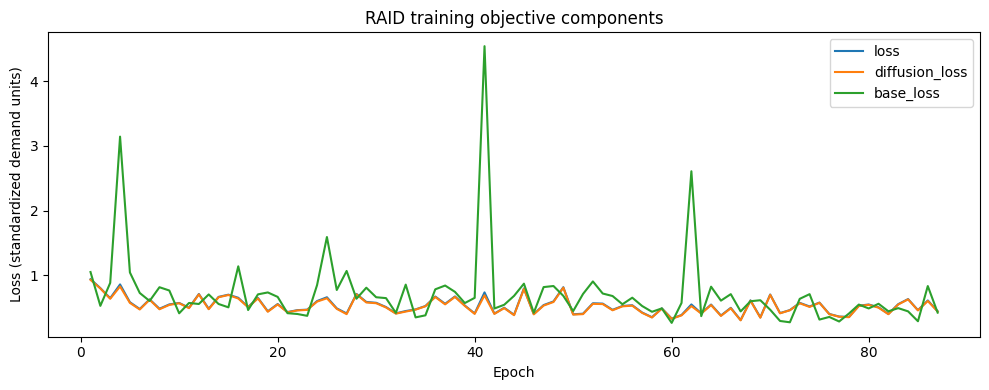

In [8]:
display(history_df.tail())
fig, ax = plt.subplots(figsize=(10, 4))
for col in ["loss", "diffusion_loss", "base_loss"]:
    ax.plot(history_df["epoch"], history_df[col], label=col)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (standardized demand units)")
ax.set_title("RAID training objective components")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluate all held-out launch cases

This section reconstructs donor sets using training SKUs only and the history strictly before each target's launch origin. Targets without a complete 13-week actual window should not be in the eligible case file. Forecasts are returned to original demand units before computing metrics.

In [9]:
@torch.no_grad()
def predict_one(target_sku, origin, model):
    target_sku = str(target_sku)
    if target_sku not in test_skus:
        raise ValueError(f"{target_sku} is not in the held-out test split.")
    hist_weeks = pd.RangeIndex(int(origin) - H, int(origin))
    donors = []
    for donor in train_skus:
        if donor == target_sku:
            continue
        if int(meta_by_sku.loc[donor, d["launch_column"]]) >= int(origin):
            continue
        donor_series = series[donor]
        hist = donor_series.reindex(hist_weeks)
        if not hist.notna().all():
            continue
        prior = donor_series.loc[donor_series.index < int(origin)].dropna()
        if len(prior) < 2:
            continue
        mu = float(prior.mean() / DEMAND_SCALE)
        sd = float(prior.std(ddof=0) / DEMAND_SCALE)
        if not np.isfinite(sd) or sd < 1e-6:
            sd = 1e-6
        donors.append((donor, hist.to_numpy(dtype=np.float32) / DEMAND_SCALE, mu, sd))
    if not donors:
        raise RuntimeError(f"No valid training donors for {target_sku} at origin {origin}.")
    target_emb = embeddings[sku_to_idx[target_sku]]
    sims = np.array([embeddings[sku_to_idx[x[0]]] @ target_emb for x in donors])
    chosen = np.argsort(-sims)[:min(int(m["neighbors_k"]), len(donors))]
    selected = [donors[j] for j in chosen]
    donor_names = [x[0] for x in selected]
    assert target_sku not in donor_names

    donor_idx = [sku_to_idx[x[0]] for x in selected]
    donor_hist = torch.as_tensor(np.stack([x[1] for x in selected]), dtype=torch.float32, device=device)
    donor_mu = torch.as_tensor([x[2] for x in selected], dtype=torch.float32, device=device)
    donor_sd = torch.as_tensor([x[3] for x in selected], dtype=torch.float32, device=device)
    was_training = model.training
    model.eval()
    try:
        samples = model.predict_samples(
            emb_t, sku_to_idx[target_sku], donor_idx, donor_hist,
            donor_mu, donor_sd, num_samples=int(cfg["evaluation"]["num_samples"]),
            inference_steps=int(m["diffusion_inference_steps"])
        ).cpu().numpy() * DEMAND_SCALE
    finally:
        model.train(was_training)
    actual = series[target_sku].reindex(pd.RangeIndex(int(origin), int(origin) + H)).to_numpy(dtype=float)
    if len(actual) != H or not np.isfinite(actual).all():
        raise ValueError(f"Incomplete target truth for {target_sku} at origin {origin}.")
    return samples, actual, donor_names


def point_metrics(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    err = p - y
    denom = np.abs(y).sum()
    smape_denom = np.abs(y) + np.abs(p)
    return {
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err**2))),
        "WAPE": float(np.abs(err).sum() / denom) if denom > 0 else np.nan,
        "sMAPE": float(np.mean(2 * np.abs(err) / np.maximum(smape_denom, 1e-8)))
    }


model.eval()
test_cases = cases[cases["target_sku"].astype(str).isin(test_skus)].copy()
prediction_rows, per_sku_rows = [], []
for _, row in test_cases.iterrows():
    sku, origin = str(row["target_sku"]), int(row["origin_week"])
    samples, actual, donor_names = predict_one(sku, origin, model)
    pred = samples.mean(axis=0)
    for step in range(H):
        prediction_rows.append({
            "target_sku": sku, "origin_week": origin, "forecast_week": origin + step,
            "step": step + 1, "actual": float(actual[step]), "prediction": float(pred[step])
        })
    per_sku_rows.append({"target_sku": sku, "origin_week": origin, **point_metrics(actual, pred),
                         "donor_count": len(donor_names), "donors": ";".join(donor_names)})

pred_df = pd.DataFrame(prediction_rows)
per_sku_df = pd.DataFrame(per_sku_rows)
metrics = point_metrics(pred_df["actual"].to_numpy(), pred_df["prediction"].to_numpy())
print("Overall metrics:", json.dumps(metrics, indent=2))
print("Test SKUs:", per_sku_df["target_sku"].nunique(), "forecast rows:", len(pred_df))
display(per_sku_df.sort_values("MAE", ascending=False).head(10))

pred_dir = ROOT / o["prediction_dir"]
pred_dir.mkdir(parents=True, exist_ok=True)
pred_df.to_csv(pred_dir / "raid_predictions_notebook.csv", index=False)
per_sku_df.to_csv(pred_dir / "raid_per_sku_metrics_notebook.csv", index=False)
(pred_dir / "raid_metrics_notebook.json").write_text(json.dumps({
    **metrics, "test_skus": int(per_sku_df["target_sku"].nunique()),
    "forecast_window_weeks": H,
    "protocol": "SKU-held-out cold-start simulation; not strict historical backtesting",
    "demand_scale": DEMAND_SCALE,
    "checkpoint": str((checkpoint_dir / "raid_best_notebook.pt").relative_to(ROOT))
}, indent=2) + "\\n", encoding="utf-8")

Overall metrics: {
  "MAE": 29334.793229038114,
  "RMSE": 34072.77335632618,
  "WAPE": 1.704010372567625,
  "sMAPE": 1.1816422368627013
}
Test SKUs: 35 forecast rows: 455


,target_sku,origin_week,MAE,RMSE,WAPE,sMAPE,donor_count,donors
3,SKU-C-3,20,49489.203726,56316.132286,1.470378,1.136112,20,SKU-C-1;SKU-C-2;SKU-B-2;SKU-B-1;SKU-A-2;SKU-F-...
31,SKU-W-4,74,45068.018930,45218.433252,10.677874,1.692026,20,SKU-C-2;SKU-O-2;SKU-N-2;SKU-Q-2;SKU-S-2;SKU-L-...
5,SKU-E-4,84,45005.706430,45074.035255,36.026735,1.897878,20,SKU-E-2;SKU-E-3;SKU-F-3;SKU-F-2;SKU-C-2;SKU-A-...
4,SKU-C-5,159,44583.031250,46328.672730,5.556903,1.514725,14,SKU-C-4;SKU-D-4;SKU-B-4;SKU-F-4;SKU-A-4;SKU-A-...
34,SKU-Y-5,163,42710.675180,52647.964459,0.635138,0.789761,14,SKU-N-4;SKU-N-3;SKU-D-4;SKU-V-4;SKU-F-4;SKU-Q-...
7,SKU-G-4,79,42351.988882,42599.769147,6.779656,1.566179,20,SKU-I-2;SKU-C-2;SKU-N-2;SKU-H-2;SKU-L-2;SKU-S-...
12,SKU-I-4,79,41240.724459,41588.011749,5.553271,1.488697,20,SKU-N-2;SKU-O-2;SKU-Q-2;SKU-Q-3;SKU-C-2;SKU-I-...
2,SKU-B-5,160,40833.850060,42086.085995,4.592320,1.458608,14,SKU-B-4;SKU-D-4;SKU-C-4;SKU-F-4;SKU-A-4;SKU-A-...
23,SKU-P-4,127,38890.421875,44878.654139,0.756677,0.743846,14,SKU-A-4;SKU-F-4;SKU-C-4;SKU-B-4;SKU-N-4;SKU-Q-...
28,SKU-T-4,76,38491.898137,39034.630842,6.509114,1.580285,20,SKU-C-2;SKU-N-2;SKU-O-2;SKU-Q-2;SKU-F-2;SKU-S-...


384

## 8. Diagnose one held-out SKU: base vs diffusion

This section uses the already-fitted model and the target's labels only for scoring/visualization. No optimizer step is performed here.

Target: SKU-T-4 origin: 76 donors: 20
Base forecast min/mean/max: 39778.14453125 44523.62890625 50169.5390625
Final forecast min/mean/max: 39629.5546875 44442.640625 49861.515625
Actual min/mean/max: 0.0 5913.538461538462 19904.0
Gate sigmoid: 0.05271298065781593


,step,actual,base,final_prediction,diffusion_correction
0,1,159.0,47726.660156,47037.667969,-688.992188
1,2,637.0,43491.207031,43933.445312,442.238281
2,3,0.0,45487.242188,45274.449219,-212.792969
3,4,637.0,44787.996094,44862.898438,74.902344
4,5,1433.0,45673.230469,45373.625000,-299.605469
5,6,3137.0,42940.097656,43059.265625,119.167969
6,7,1592.0,43270.371094,42894.023438,-376.347656
7,8,8598.0,50169.539062,49861.515625,-308.023438
8,9,5334.0,39778.144531,39629.554688,-148.589844
9,10,6942.0,41469.199219,41328.492188,-140.707031


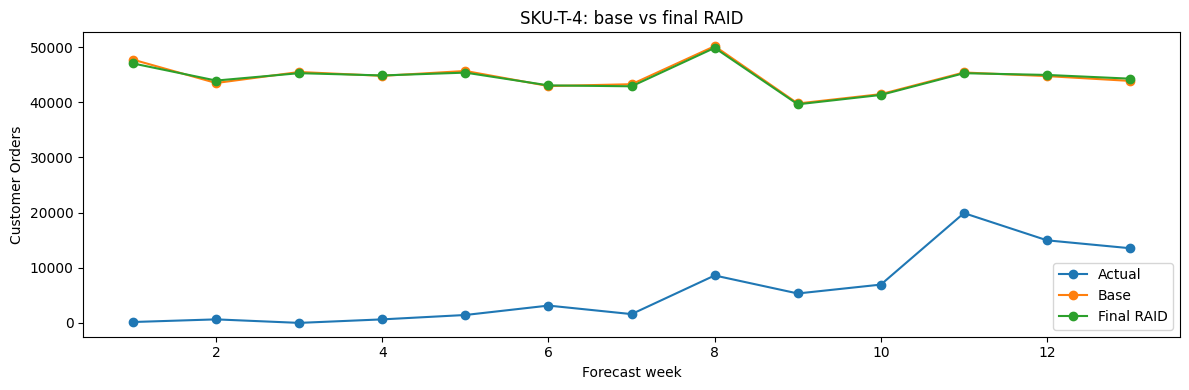

In [12]:
TARGET_SKU = "SKU-T-4"#str(test_cases.iloc[0]["target_sku"])
case = test_cases[test_cases["target_sku"].astype(str) == TARGET_SKU].iloc[0]
origin = int(case["origin_week"])
samples, actual, donor_names = predict_one(TARGET_SKU, origin, model)
final = samples.mean(axis=0)

# Rebuild tensors to inspect the base forecast separately.
selected = []
hist_weeks = pd.RangeIndex(origin - H, origin)
for donor in train_skus:
    if int(meta_by_sku.loc[donor, d["launch_column"]]) >= origin:
        continue
    hs = series[donor].reindex(hist_weeks)
    if not hs.notna().all():
        continue
    prior = series[donor].loc[series[donor].index < origin].dropna()
    if len(prior) < 2:
        continue
    mu, sd = float(prior.mean()/DEMAND_SCALE), float(prior.std(ddof=0)/DEMAND_SCALE)
    if not np.isfinite(sd) or sd < 1e-6: sd = 1e-6
    selected.append((donor, hs.to_numpy(np.float32)/DEMAND_SCALE, mu, sd))
sim = np.array([embeddings[sku_to_idx[x[0]]] @ embeddings[sku_to_idx[TARGET_SKU]] for x in selected])
order = np.argsort(-sim)[:min(int(m["neighbors_k"]), len(selected))]
selected = [selected[j] for j in order]
di = torch.tensor([[sku_to_idx[x[0]] for x in selected]], dtype=torch.long, device=device)
dh = torch.tensor(np.stack([x[1] for x in selected])[None], dtype=torch.float32, device=device)
dm = torch.tensor(np.array([x[2] for x in selected])[None,:,None], dtype=torch.float32, device=device)
ds = torch.tensor(np.array([x[3] for x in selected])[None,:,None], dtype=torch.float32, device=device)
ti = torch.tensor([sku_to_idx[TARGET_SKU]], dtype=torch.long, device=device)

was_training = model.training
model.eval()
with torch.no_grad():
    raw, compact, context, _ = model.graph(emb_t)
    base_std, weights, pred_scale, pred_mean = model.base_forecast(
        raw[ti], compact[ti], raw[di], dh, dm, ds,
        torch.ones((1, len(selected)), dtype=torch.bool, device=device)
    )
    base = base_std.squeeze(0).cpu().numpy() * DEMAND_SCALE
    gate = float(torch.sigmoid(model.gate(context[ti])).item())
model.train(was_training)

print("Target:", TARGET_SKU, "origin:", origin, "donors:", len(selected))
print("Base forecast min/mean/max:", float(base.min()), float(base.mean()), float(base.max()))
print("Final forecast min/mean/max:", float(final.min()), float(final.mean()), float(final.max()))
print("Actual min/mean/max:", float(actual.min()), float(actual.mean()), float(actual.max()))
print("Gate sigmoid:", gate)
display(pd.DataFrame({
    "step": np.arange(1, H+1), "actual": actual, "base": base,
    "final_prediction": final, "diffusion_correction": final-base
}))
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(range(1,H+1), actual, marker="o", label="Actual")
ax.plot(range(1,H+1), base, marker="o", label="Base")
ax.plot(range(1,H+1), final, marker="o", label="Final RAID")
ax.set_xlabel("Forecast week")
ax.set_ylabel("Customer Orders")
ax.set_title(f"{TARGET_SKU}: base vs final RAID")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Exporting the final implementation

After the notebook is run end to end and its checks pass, move:

- **Architecture cell** → `src/models/raid.py`
- **EpisodeDataset + collate cell** → `scripts/train_raid_aggregate.py`
- **Training cell** → the `main()` training body in that script
- **Evaluation cells** → `scripts/evaluate_raid_aggregate.py`

Before declaring a final result, run ablations for (a) base-only, (b) paper-objective RAID with DDPM sampling, and (c) any optional gate auxiliary loss or alternative sampler. Do not select variants using the held-out test labels.

This notebook's code is a corrected, paper-guided candidate architecture—not a verified exact reproduction of the RAID authors' implementation. Keep that distinction in the report.